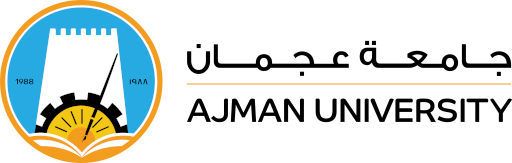

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Fall 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Dr. Mahmoud AlShboul<br>
</p></center>

Student ID: _________________<br />
Student Name: _______________________

# **Lab 3 - Machine Learning - Classification**

## Support Vector Machines
Support Vector Machines is considered to be a classification approach, it but can be employed in both types of classification and regression problems. It can easily handle multiple continuous and categorical variables. SVM constructs a hyperplane in multidimensional space to separate different classes. SVM generates optimal hyperplane in an iterative manner, which is used to minimize an error. The core idea of SVM is to find a maximum marginal hyperplane(MMH) that best divides the dataset into classes.

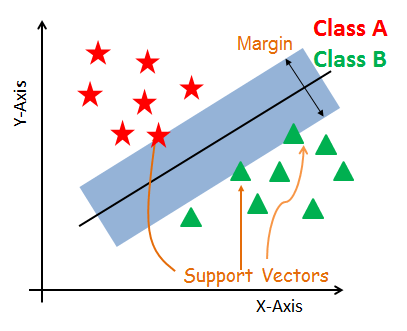

The main objective is to segregate the given dataset in the best possible way. The distance between the either nearest points is known as the margin. The objective is to select a hyperplane with the maximum possible margin between support vectors in the given dataset. SVM searches for the maximum marginal hyperplane in the following steps:

1. Generate hyperplanes which segregates the classes in the best way. Left-hand side figure showing three hyperplanes black, blue and orange. Here, the blue and orange have higher classification error, but the black is separating the two classes correctly.

2. Select the right hyperplane with the maximum segregation from the either nearest data points as shown in the right-hand side figure.

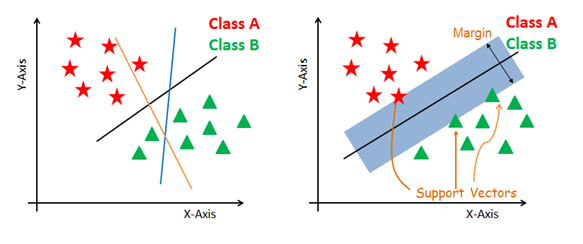


The SVM algorithm is implemented in practice using a kernel. A kernel transforms an input data space into the required form. SVM uses a technique called the kernel trick. Here, the kernel takes a low-dimensional input space and transforms it into a higher dimensional space. In other words, you can say that it converts nonseparable problem to separable problems by adding more dimension to it. It is most useful in non-linear separation problem. Kernel trick helps you to build a more accurate classifier.
1. **Linear Kernel**: A linear kernel can be used as normal dot product any two given observations. The product between two vectors is the sum of the multiplication of each pair of input values.
2. **Polynomial Kernel**: A polynomial kernel is a more generalized form of the linear kernel. The polynomial kernel can distinguish curved or nonlinear input space.
3. **Radial Basis Function Kernel**: The Radial basis function kernel is a popular kernel function commonly used in support vector machine classification. RBF can map an input space in infinite dimensional space.

### SVM in Scikit Learn

In [1]:
from sklearn import datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# np.c_[ ... ] → stacks arrays column-wise.
#   Here, it combines the features (cancer['data']) and the target labels (cancer['target']) into a single NumPy array.

# pd.DataFrame(..., columns=...) → creates a pandas DataFrame:
#   The data is the combined NumPy array (features + target).
#   The column names are feature_names plus an extra column 'target' (so the labels are included).

cancer = datasets.load_breast_cancer()
df = pd.DataFrame(np.c_[cancer['data'], cancer['target']],
                  columns= np.append(cancer['feature_names'], ['target']))
df.head(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0.0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0.0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0.0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0.0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0.0
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0.0
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0.0
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0.0
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0.0
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0.0


In [ ]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# : → means all rows
# :-1 → means all columns except the last one
# So x will contain:
#   All feature columns (the 30 measurements from the dataset)
#   Without the target column
x = df.iloc[:,:-1]


# : → all rows
# -1 → only the last column
# So y will contain:
#   Just the target column (0 = malignant, 1 = benign)
y = df.iloc[:,-1]


# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=109) # 70% training and 30% test
# random_state=109
#   Ensures the split is reproducible.
#   Without it, every run could shuffle differently.
#   With it, you always get the same split.


In [ ]:
#Import svm model
from sklearn import svm

#Create a svm Classifier
clf = svm.SVC(kernel='linear') # Linear Kernel
# kernel='linear' → tells the SVM to use a linear kernel, meaning:
# The algorithm will try to separate the classes (malignant vs. benign) with a straight line (or hyperplane in higher dimensions).
# In this dataset (30 features), that’s a 30-dimensional hyperplane.

#Train the model using the training sets
clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [5]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.9649122807017544


In [6]:
# Model Precision: what percentage of positive tuples are labeled as such?
print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
print("Recall:",metrics.recall_score(y_test, y_pred))


Precision: 0.9811320754716981
Recall: 0.9629629629629629


## Neural Networks in TensorFlow

In [17]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [18]:
cancer = datasets.load_breast_cancer()
df = pd.DataFrame(np.c_[cancer['data'], cancer['target']],
                  columns= np.append(cancer['feature_names'], ['target']))
x = df.iloc[:,:-1]
y = df.iloc[:,-1]
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3,random_state=109) # 70% training and 30% test


scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)


In [ ]:
#defining the tensorflow model
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# tf.keras.models.Sequential([...])
#   Creates a Sequential model, which is a linear stack of layers.
#   Each layer feeds into the next one.
# tf.keras.layers.Input(shape=(30,))
#   Specifies the input shape of the data.
#   (30,) → your dataset has 30 features (columns from the breast cancer dataset).
#   This tells the network how many inputs to expect.
# tf.keras.layers.Dense(16, activation='relu')
#   Adds a fully connected (Dense) hidden layer with 16 neurons.
#   activation='relu' → applies the ReLU activation function (Rectified Linear Unit):
#   ReLU = max(0, x)
#   Introduces non-linearity, allowing the network to learn more complex patterns.
# tf.keras.layers.Dense(1, activation='sigmoid')
#   Adds the output layer with 1 neuron.
#   activation='sigmoid' → squashes output to a range [0, 1], which is perfect for binary classification (malignant vs. benign).
#   The output can be interpreted as the probability of the positive class (target=1).

In [ ]:
#summary of the model
model.summary()
# Prints a summary of your neural network architecture.
# Shows key details about each layer, including:
#   Layer type (Dense, Input, etc.)
#   Output shape of each layer
#   Number of parameters (weights + biases) in each layer

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 16)                496       
                                                                 
 dense_1 (Dense)             (None, 1)                 17        
                                                                 
Total params: 513 (2.00 KB)
Trainable params: 513 (2.00 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
#Compilation of the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# optimizer='adam'
# Adam is an optimization algorithm that adjusts the weights of the network during training.
# Combines the benefits of:
# Momentum (accelerates convergence)
# Adaptive learning rates (adjusts learning for each parameter)
# Popular because it usually works well without much tuning.

# loss='binary_crossentropy'
#   Binary Crossentropy is the loss function used for binary classification problems.
#   Measures how far the predicted probabilities are from the true labels.
#   Formula (for one sample):
#       Loss=−(y⋅log⁡(p)+(1−y)⋅log⁡(1−p))
#       Loss=−(y⋅log(p)+(1−y)⋅log(1−p))
#       where:
#           y = true label (0 or 1)
#           p = predicted probability from sigmoid
#       The optimizer tries to minimize this loss during training.

# metrics=['accuracy']
#   Accuracy is calculated during training/validation for monitoring.
#   Shows the proportion of correctly predicted samples.
#   Other metrics could include AUC, precision, recall, etc., but here you’re just tracking accuracy.

In [ ]:
model.fit(x_train_scaled, y_train, epochs=100)
# x_train_scaled
#   The training features, usually scaled/normalized.
#   Neural networks perform better when input features are on a similar scale (e.g., 0–1 or standardized with mean 0, std 1).
# y_train
#   The target labels for training (0 = malignant, 1 = benign).
# epochs=100
#   Epoch = one complete pass through the entire training dataset.
#   Setting epochs=100 means the model will see every training sample 100 times.
#   Each epoch updates the weights using backpropagation and the optimizer (Adam in this case).

Epoch 1/100
13/13 [==============================] - 1s 4ms/step - loss: 0.6971 - accuracy: 0.6407
Epoch 2/100
13/13 [==============================] - 0s 3ms/step - loss: 0.5515 - accuracy: 0.7990
Epoch 3/100
13/13 [==============================] - 0s 3ms/step - loss: 0.4461 - accuracy: 0.8668
Epoch 4/100
13/13 [==============================] - 0s 2ms/step - loss: 0.3693 - accuracy: 0.8995
Epoch 5/100
13/13 [==============================] - 0s 4ms/step - loss: 0.3148 - accuracy: 0.9246
Epoch 6/100
13/13 [==============================] - 0s 2ms/step - loss: 0.2749 - accuracy: 0.9347
Epoch 7/100
13/13 [==============================] - 0s 3ms/step - loss: 0.2449 - accuracy: 0.9422
Epoch 8/100
13/13 [==============================] - 0s 3ms/step - loss: 0.2222 - accuracy: 0.9447
Epoch 9/100
13/13 [==============================] - 0s 2ms/step - loss: 0.2045 - accuracy: 0.9472
Epoch 10/100
13/13 [==============================] - 0s 2ms/step - loss: 0.1898 - accuracy: 0.9472
Epoch 11/

In [ ]:
#Evaluating the NN with test data
_, accuracy = model.evaluate(x_test_scaled, y_test)
print('Accuracy:', accuracy)
# model.evaluate(x_test_scaled, y_test)
#   Evaluates the trained neural network on the test data (unseen during training).
#   Returns a list of metrics specified during compile():
#       First element = loss (binary_crossentropy)
#       Second element = accuracy (because metrics=['accuracy'])
#   Using _ for the first value means we ignore the loss and only care about accuracy.
# x_test_scaled, y_test
#   Test features and labels must match the training scale (hence x_test_scaled).
#   Ensures predictions are consistent.
# print('Accuracy:', accuracy)
#   Prints the accuracy on the test set — how well your model generalizes to unseen data.
#   Accuracy = (number of correct predictions) ÷ (total test samples)

6/6 [==============================] - 0s 2ms/step - loss: 0.0370 - accuracy: 0.9883
Accuracy: 0.988304078578949


In [ ]:
#saving the model in a .keras zipped archive
model.save('breast_cancer_svm_mdl.keras')
# Saves the entire trained neural network to a file called 'breast_cancer_svm_mdl.keras'.
# This includes:
#   Model architecture (layers, activations, shapes)
#   Trained weights (all the learned parameters)
#   Optimizer state (so you could resume training if needed)
# The .keras extension indicates it’s saved in the Keras native format.

# How to load it later
# from tensorflow.keras.models import load_model
# loaded_model = load_model('breast_cancer_svm_mdl.keras')
# After loading, loaded_model behaves just like the original model.
# You can predict, evaluate, or continue training without having to retrain from scratch.

# QUESTIONS
1. Load the 'electrical_grid' dataset into a pandas dataframe
2. Implement and evaluate a Support Vector classifier using Sci-kit learn and compare it to using a neural network tensorflow model.
3. Discuss the results of the two models.

In [ ]:
# SVM


In [ ]:
# Neural Network


In [ ]:
# Comparison


## BONUS

### Support Vector Machines in PyCaret

In [ ]:
# !pip install -q pycaret

In [ ]:
# # Imports the ClassificationExperiment class from PyCaret’s classification module.
# # PyCaret wraps a lot of scikit-learn functionality but automates:
# #   preprocessing (encoding, scaling, missing values, etc.)
# #   model comparison
# #   hyperparameter tuning
# #   evaluation plots
# from pycaret.classification import ClassificationExperiment

# # Creates an experiment object (s) for classification.
# # Think of it as a "workspace" that keeps track of your dataset, preprocessing steps, and models.
# s = ClassificationExperiment()


# # Initializes the experiment setup:
# #   df → your full DataFrame (features + target).
# #   target='target' → tells PyCaret which column is the label (the class you want to predict: benign/malignant).
# #   session_id=123 → fixes the random seed to ensure reproducibility.
# s.setup(df, target = 'target', session_id = 123)

# # During setup, PyCaret automatically:
# #   Splits train/test for you.
# #   Encodes categorical features (if any).
# #   Normalizes/standardizes numeric features if needed.
# #   Handles missing values.
# #   Prepares the data so that you can directly start comparing models.

In [ ]:
# #svm classifier
# svm_model = s.create_model('svm')
# # s.create_model('svm') → tells PyCaret to train a Support Vector Machine (SVM) classifier on your dataset.
# # Because we already ran s.setup(...), PyCaret knows:
# #   what features (x) are,
# #   what target (y) is,
# #   how to preprocess them.
# # The 'svm' string is a model short code in PyCaret.
# # Some examples:
# #   'lr' → Logistic Regression
# #   'rf' → Random Forest
# #   'knn' → K-Nearest Neighbors
# #   'svm' → Support Vector Machine

In [ ]:
# #evaluating the model
# s.evaluate_model(svm_model)
# # Opens up an interactive dashboard (GUI) in the notebook/IDE.
# # Lets us visually analyze the performance of the trained svm_model.
# # Typical plots include:
# #   Confusion Matrix → how many benign/malignant cases were correctly/incorrectly classified.
# #   ROC Curve → tradeoff between True Positive Rate and False Positive Rate.
# #   Precision-Recall Curve → useful when dealing with imbalanced datasets.
# #   Learning Curve → shows if the model is overfitting/underfitting.
# #   Feature Importance → shows which features the model relies on most (though SVM linear models make this clearer than RBF ones).
# #   Lift Curve / Gain Chart → compares model performance vs random guessing.
# #   Calibration Curve → checks how well predicted probabilities match reality.

In [ ]:
# s.plot_model(svm_model,'pr')
# # plot_model() → generates specific plots for a trained model.
# #   First argument: the model object (svm_model).
# #   Second argument: the type of plot you want.
# #   Here: 'pr' means Precision-Recall curve.
# # Precision-Recall (PR) Curve
# #   Precision = out of the patients the model predicted as malignant, how many were actually malignant?
# #   Recall = out of the patients that were truly malignant, how many did the model correctly detect?
# #   The PR curve shows the trade-off between precision and recall at different classification thresholds.

In [ ]:
# #tune the model
# tuned_svm_model = s.tune_model(svm_model)
# # tune_model() → automatically tunes the hyperparameters of the given model.
# #   Input: your already-trained model (svm_model).
# #   Output: a new model (tuned_svm_model) with better hyperparameters found through optimization.

# # It uses Grid Search / Random Search / Bayesian optimization (depending on the algorithm) to 
# # find hyperparameters that improve performance.
# # For SVM (svm), typical hyperparameters include:
# #   C → regularization parameter (controls margin vs. misclassification tradeoff).
# #   kernel → type of decision boundary (linear, poly, rbf, sigmoid).
# #   gamma → kernel coefficient (for rbf, poly, sigmoid).
# # PyCaret tries different combinations, evaluates using cross-validation, 
# # and picks the set that yields the best results (by default, it optimizes 
# # for Accuracy, but you can specify another metric).

In [ ]:
# #generate predictions with the model
# s.predict_model(tuned_svm_model)
# # predict_model() → makes predictions on the holdout/test set that PyCaret created during setup().
# #   Input: your trained and tuned model (tuned_svm_model).
# #   Output: a DataFrame that includes:
# #       Original features
# #       Actual target (target)
# #       Predicted labels (Label)
# #       Prediction probabilities for each class (Score or Score_0, Score_1)